# Aula 03 — Análise de Vendas em Python

**Aluno:** Davi Horácio de Souza · **Matrícula:** 20250059934

Neste exercício refaço o roteiro da aula 3 e completo o "Para casa": responder ao briefing de um gerente de vendas usando o **Online Retail**, definindo e justificando o que conta como venda válida, cancelamento, devolução e registro anômalo.

O trabalho continua no projeto de vendas da [`Unidade_01`](..), com os dados em `Unidade_01/data/`. Os comandos de terminal aparecem em blocos `bash` com a saída obtida, e o código fica em células executáveis. Cada resultado é seguido de uma análise.

## 1. Retomando o projeto

```bash
cd ..
uv pip install matplotlib
uv pip freeze > requirements.txt
cat requirements.txt
```

Saída:

```text
Resolved 11 packages in 2.29s
Downloading kiwisolver (1.4MiB)
Downloading fonttools (5.2MiB)
Downloading pillow (6.8MiB)
Downloading matplotlib (9.4MiB)
 Downloaded kiwisolver
 Downloaded fonttools
 Downloaded pillow
 Downloaded matplotlib
Prepared 5 packages in 8.23s
Installed 8 packages in 76ms
 + contourpy==1.4.0
 + cycler==0.12.1
 + fonttools==4.68.0
 + kiwisolver==1.5.1
 + matplotlib==3.11.2
 + packaging==26.3
 + pillow==13.0.0
 + pyparsing==3.3.3
contourpy==1.4.0
cycler==0.12.1
et-xmlfile==2.0.0
fonttools==4.68.0
kiwisolver==1.5.1
matplotlib==3.11.2
numpy==2.5.5
openpyxl==3.1.5
packaging==26.3
pandas==3.1.1
pillow==13.0.0
pyparsing==3.3.3
python-dateutil==4.0.0
tzdata==2026.6
```

**Análise:** o roteiro da aula usa só pandas e openpyxl, mas o "Para casa" pede a evolução mensal do faturamento, e um gráfico mostra a sazonalidade muito melhor que uma tabela. Por isso instalei o **matplotlib** no ambiente da unidade e atualizei o `requirements.txt`. Junto vieram as dependências dele (pillow, fonttools etc.), e todas ficaram registradas com versão fixa.

## 2. O enunciado

> O gerente de vendas quer entender o desempenho comercial do último ano e encontrar caminhos para aumentar o faturamento: quais produtos, clientes, países e períodos priorizar, e o que prejudica o resultado.

A análise precisa responder:

1. Quais produtos lideram em **faturamento**, **volume** e **frequência de compra**?
2. Quais **países** e **clientes** são mais relevantes?
3. Qual o **valor médio dos pedidos**?
4. Qual o **impacto financeiro** dos cancelamentos e devoluções?
5. Há **outliers** e problemas de qualidade que distorcem os números?
6. Como o faturamento **evolui mês a mês**, e há sazonalidade?

Antes de responder, é preciso definir e justificar o que conta como **venda válida**, **cancelamento**, **devolução** e **registro anômalo**.

## 3. Preparando os dados

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
caminho_dados = Path("..") / "data" / "online_retail.xlsx"

nomes_colunas = {
    "InvoiceNo": "invoice_no",
    "StockCode": "stock_code",
    "Description": "description",
    "Quantity": "quantity",
    "InvoiceDate": "invoice_date",
    "UnitPrice": "unit_price",
    "CustomerID": "customer_id",
    "Country": "country",
}
colunas_originais = list(nomes_colunas.values())

retail = pd.read_excel(caminho_dados).rename(columns=nomes_colunas)

retail["invoice_no"] = retail["invoice_no"].astype(str)
retail["stock_code"] = retail["stock_code"].astype(str)
retail["customer_id"] = retail["customer_id"].astype("Int64")
retail["invoice_date"] = pd.to_datetime(retail["invoice_date"], errors="coerce")
retail["revenue"] = retail["quantity"] * retail["unit_price"]
retail["is_cancelled"] = retail["invoice_no"].str.startswith("C")

linhas, colunas = retail.shape
print(f"{linhas:,} linhas × {colunas} colunas")
retail.dtypes

541,909 linhas × 10 colunas


invoice_no                 str
stock_code                 str
description             object
quantity                 int64
invoice_date    datetime64[us]
unit_price             float64
customer_id              Int64
country                    str
revenue                float64
is_cancelled              bool
dtype: object

**Análise:** além de renomear as colunas, preparei os tipos e criei duas colunas novas. `invoice_no` e `stock_code` viraram texto, porque misturam números com letras (`C536379`, `85123A`) e precisam de um tipo só. `customer_id` virou `Int64`, o inteiro do pandas que aceita ausentes (`<NA>`): resolve o problema do `float64` visto na Aula 02. A coluna `revenue` (quantidade × preço) é o faturamento de cada linha, e `is_cancelled` marca as notas que começam com `C`. A base passa a ter 10 colunas.

## 4. Visão geral da base

In [3]:
print(f"Período: {retail['invoice_date'].min()} a {retail['invoice_date'].max()}")
print(f"Notas fiscais: {retail['invoice_no'].nunique():,}")
print(f"Clientes identificados: {retail['customer_id'].nunique():,}")
print(f"Produtos (códigos): {retail['stock_code'].nunique():,}")
print(f"Países: {retail['country'].nunique()}")

Período: 2010-12-01 08:26:00 a 2011-12-09 12:50:00
Notas fiscais: 25,900
Clientes identificados: 4,372
Produtos (códigos): 4,070
Países: 38


**Análise:** a base cobre pouco mais de um ano (01/12/2010 a 09/12/2011), com **25.900 notas fiscais**, **4.372 clientes identificados**, **4.070 códigos de produto** e **38 países**. São esses números que vão servir de denominador para os indicadores das próximas seções.

In [4]:
retail[["quantity", "unit_price", "revenue"]].describe().round(2)

,quantity,unit_price,revenue
count,541909.00,541909.00,541909.00
mean,9.55,4.61,17.99
std,218.08,96.76,378.81
min,-80995.00,-11062.06,-168469.60
25%,1.00,1.25,3.40
50%,3.00,2.08,9.75
75%,10.00,4.13,17.40
max,80995.00,38970.00,168469.60


**Análise:** a coluna `revenue` herda os extremos das outras: vai de **−£ 168.469,60 a +£ 168.469,60**, exatamente o mesmo valor com sinais opostos. É a pista de uma venda gigante que foi estornada, investigada na seção 9.2. A mediana do faturamento por linha é de só £ 9,75, então a base é feita de muitas linhas pequenas e alguns valores extremos.

## 5. Qualidade dos dados

In [5]:
ausentes = pd.DataFrame(
    {
        "ausentes": retail[colunas_originais].isna().sum(),
        "percentual": (retail[colunas_originais].isna().mean() * 100).round(2),
    }
).sort_values("ausentes", ascending=False)
ausentes

,ausentes,percentual
customer_id,135080,24.93
description,1454,0.27
stock_code,0,0.00
invoice_no,0,0.00
quantity,0,0.00
invoice_date,0,0.00
unit_price,0,0.00
country,0,0.00


**Análise:** os ausentes estão concentrados em duas colunas: **24,93% das linhas sem cliente** e 0,27% sem descrição. A falta de descrição é pequena, mas a de cliente é grande e vai limitar o ranking de clientes (seção 7.4), que só pode usar as vendas identificadas.

In [6]:
duplicadas = retail.duplicated(subset=colunas_originais)
print(f"Linhas duplicadas: {duplicadas.sum():,} ({duplicadas.mean():.2%})")

Linhas duplicadas: 5,268 (0.97%)


**Análise:** **5.268 linhas (0,97%)** são cópias exatas. Como no roteiro, só registro o problema por enquanto. A decisão de mantê-las está justificada nos critérios da seção 9.3.

In [7]:
problemas = pd.Series(
    {
        "Faturas canceladas": retail["is_cancelled"].sum(),
        "Quantidade negativa": retail["quantity"].lt(0).sum(),
        "Quantidade igual a zero": retail["quantity"].eq(0).sum(),
        "Preço negativo": retail["unit_price"].lt(0).sum(),
        "Preço igual a zero": retail["unit_price"].eq(0).sum(),
        "Descrição ausente": retail["description"].isna().sum(),
        "Cliente não identificado": retail["customer_id"].isna().sum(),
        "Data inválida ou ausente": retail["invoice_date"].isna().sum(),
    },
    name="linhas",
)
problemas

Faturas canceladas            9288
Quantidade negativa          10624
Quantidade igual a zero          0
Preço negativo                   2
Preço igual a zero            2515
Descrição ausente             1454
Cliente não identificado    135080
Data inválida ou ausente         0
Name: linhas, dtype: int64

**Análise:** a tabela reúne num lugar só todos os problemas da base: 9.288 linhas de notas canceladas, 10.624 com quantidade negativa, 2.515 com preço zero, **2 com preço negativo** e 135.080 sem cliente. Não há quantidade zero nem data inválida. Cada problema pede uma regra no filtro de vendas válidas.

In [8]:
retail[["quantity", "unit_price"]].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2)

,quantity,unit_price
count,541909.00,541909.00
mean,9.55,4.61
std,218.08,96.76
min,-80995.00,-11062.06
1%,-2.00,0.19
25%,1.00,1.25
50%,3.00,2.08
75%,10.00,4.13
99%,100.00,18.00
max,80995.00,38970.00


**Análise:** os percentis mostram o quanto os extremos estão longe do comportamento normal: **98% das linhas têm quantidade entre −2 e 100** e 99% têm preço até £ 18. Já os máximos são 80.995 unidades e £ 38.970. Médias calculadas com esses extremos não representam a venda típica.

## 6. Isolando as vendas válidas

In [9]:
filtro_venda_valida = ~retail["is_cancelled"] & retail["quantity"].gt(0) & retail["unit_price"].gt(0)
vendas = retail.loc[filtro_venda_valida].copy()

print(f"Linhas: {len(vendas):,}")
print(f"Pedidos: {vendas['invoice_no'].nunique():,}")
print(f"Clientes: {vendas['customer_id'].nunique():,}")
print(f"Unidades vendidas: {vendas['quantity'].sum():,}")
print(f"Faturamento bruto: £ {vendas['revenue'].sum():,.2f}")

Linhas: 530,104
Pedidos: 19,960
Clientes: 4,338
Unidades vendidas: 5,588,376
Faturamento bruto: £ 10,666,684.54


**Análise:** o filtro do roteiro (nota sem `C`, quantidade e preço positivos) mantém **530.104 linhas (97,8% da base)**, com **19.960 pedidos** e um **faturamento bruto de £ 10.666.684,54**. Das 25.900 notas, 3.836 são cancelamentos e outras 2.104 só têm linhas de preço zero ou ajustes, por isso sobram menos pedidos que notas. Esse é o ponto de partida. A seção 9.3 mostra que ele ainda inclui registros que não são venda de mercadoria.

## 7. Indicadores de pedidos, produtos, países e clientes

### 7.1 Valor médio dos pedidos

In [10]:
pedidos = vendas.groupby("invoice_no", as_index=False).agg(
    order_date=("invoice_date", "min"),
    customer_id=("customer_id", "first"),
    country=("country", "first"),
    item_quantity=("quantity", "sum"),
    order_value=("revenue", "sum"),
)

pd.Series(
    {"ticket_medio": pedidos["order_value"].mean(), "ticket_mediano": pedidos["order_value"].median()},
    name="valor_em_libras",
).round(2)

ticket_medio      534.40
ticket_mediano    303.84
Name: valor_em_libras, dtype: float64

**Análise:** o **ticket médio é £ 534,40, mas o mediano é £ 303,84**. A média fica 76% acima da mediana porque alguns pedidos enormes puxam a média para cima. Para o gerente, a mediana descreve melhor o "pedido típico": metade dos pedidos fica abaixo de £ 304.

In [11]:
pedidos["order_value"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2)

count     19960.00
mean        534.40
std        1780.49
min           0.38
25%         152.51
50%         303.84
75%         495.62
90%         940.89
99%        4821.17
max      168469.60
Name: order_value, dtype: float64

**Análise:** 75% dos pedidos ficam abaixo de £ 495,62 e 90% abaixo de £ 940,89, mas o máximo chega a **£ 168.469,60**, quase 35 vezes o percentil 99 (£ 4.821,17). O desvio-padrão (£ 1.780) é maior que três tickets médios. A distribuição tem uma cauda longa, com poucos pedidos muito grandes.

### 7.2 Produtos com maior faturamento, volume e frequência

In [12]:
produtos = vendas.dropna(subset=["description"]).groupby(["stock_code", "description"], as_index=False).agg(
    units_sold=("quantity", "sum"),
    revenue=("revenue", "sum"),
    order_count=("invoice_no", "nunique"),
)
produtos.nlargest(10, "revenue").round(2)

,stock_code,description,units_sold,revenue,order_count
4150,DOT,DOTCOM POSTAGE,706,206248.77,706
1340,22423,REGENCY CAKESTAND 3 TIER,13879,174484.74,1988
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
3640,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189
2877,47566,PARTY BUNTING,18295,99504.33,1685
3619,85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
4151,M,Manual,7224,78110.27,289
4153,POST,POSTAGE,3150,78101.88,1126
2029,23084,RABBIT NIGHT LIGHT,30788,66964.99,994


**Análise:** o ranking por faturamento tem três problemas: o **1º lugar é `DOTCOM POSTAGE`**, que é frete e não produto, e `Manual` e `POSTAGE` também aparecem. O 3º lugar, `PAPER CRAFT , LITTLE BIRDIE`, teve **um único pedido**, que foi estornado minutos depois (seção 9.2). Entre os produtos reais, o `REGENCY CAKESTAND 3 TIER` lidera com £ 174 mil.

In [13]:
produtos.nlargest(10, "units_sold").round(2)

,stock_code,description,units_sold,revenue,order_count
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
3128,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047,13841.85,535
3619,85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089
3640,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189
1129,22197,POPCORN HOLDER,36761,34298.87,803
3416,84879,ASSORTED COLOUR BIRD ORNAMENT,36461,59094.93,1455
448,21212,PACK OF 72 RETROSPOT CAKE CASES,36419,21259.10,1320
2029,23084,RABBIT NIGHT LIGHT,30788,66964.99,994
1405,22492,MINI PAINT SET VINTAGE,26633,16937.82,380


**Análise:** por volume, os dois primeiros lugares vêm de pedidos isolados gigantes: o PAPER CRAFT (80.995 unidades num único pedido) e a STORAGE JAR (78.033, das quais 74.215 num pedido estornado). Também aparece a diferença entre volume e valor: o `WORLD WAR 2 GLIDERS` vende 55 mil unidades, mas fatura só £ 13,8 mil, porque é um item muito barato.

In [14]:
produtos.nlargest(10, "order_count").round(2)

,stock_code,description,units_sold,revenue,order_count
3640,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37599,104340.29,2189
3619,85099B,JUMBO BAG RED RETROSPOT,48474,94340.05,2089
1340,22423,REGENCY CAKESTAND 3 TIER,13879,174484.74,1988
2877,47566,PARTY BUNTING,18295,99504.33,1685
179,20725,LUNCH BAG RED RETROSPOT,19353,35752.01,1564
3416,84879,ASSORTED COLOUR BIRD ORNAMENT,36461,59094.93,1455
1630,22720,SET OF 3 CAKE TINS PANTRY DESIGN,7493,38158.39,1385
448,21212,PACK OF 72 RETROSPOT CAKE CASES,36419,21259.10,1320
182,20727,LUNCH BAG BLACK SKULL.,12240,22421.21,1273
1373,22457,NATURAL SLATE HEART CHALKBOARD,9172,28147.96,1249


**Análise:** o ranking por frequência (número de pedidos diferentes) é o mais confiável dos três, porque um pedido gigante conta só uma vez. O `WHITE HANGING HEART T-LIGHT HOLDER` aparece em **2.189 pedidos**, e o `JUMBO BAG RED RETROSPOT` e o `REGENCY CAKESTAND` vêm logo atrás. São os produtos que mais clientes compram de forma recorrente: os carros-chefe do catálogo.

### 7.3 Países mais relevantes para o negócio

In [15]:
paises = vendas.groupby("country", as_index=False).agg(
    revenue=("revenue", "sum"),
    order_count=("invoice_no", "nunique"),
    customer_count=("customer_id", "nunique"),
    units_sold=("quantity", "sum"),
)
paises["share"] = (paises["revenue"] / paises["revenue"].sum() * 100).round(2)
paises.nlargest(10, "revenue").round(2)

,country,revenue,order_count,customer_count,units_sold,share
36,United Kingdom,9025222.08,18019,3920,4662390,84.61
24,Netherlands,285446.34,94,9,200361,2.68
10,EIRE,283453.96,288,3,147173,2.66
14,Germany,228867.14,457,94,119261,2.15
13,France,209715.11,392,87,112103,1.97
0,Australia,138521.31,57,9,83901,1.30
31,Spain,61577.11,90,30,27940,0.58
33,Switzerland,57089.90,54,21,30629,0.54
3,Belgium,41196.34,98,25,23237,0.39
32,Sweden,38378.33,36,8,36083,0.36


**Análise:** o Reino Unido responde por **84,61% do faturamento**. Entre os outros países há uma diferença importante: a Holanda (2º lugar, £ 285 mil) tem só **9 clientes**, e um único deles (14646) responde por 98% do faturamento do país. A Irlanda (EIRE) tem 3 clientes, dois deles com 92% do valor, e na Austrália um cliente responde por 90%. Já a Alemanha e a França têm cerca de 90 clientes cada: faturam um pouco menos, mas com uma base bem mais diversificada.

### 7.4 Clientes mais relevantes para o negócio

In [16]:
clientes = vendas.dropna(subset=["customer_id"]).groupby("customer_id", as_index=False).agg(
    revenue=("revenue", "sum"),
    order_count=("invoice_no", "nunique"),
    units_sold=("quantity", "sum"),
    country=("country", "first"),
)
top10_clientes = clientes.nlargest(10, "revenue")
print(f"Os 10 maiores clientes somam {top10_clientes['revenue'].sum() / clientes['revenue'].sum():.1%} do faturamento identificado")
top10_clientes.round(2)

Os 10 maiores clientes somam 17.3% do faturamento identificado


,customer_id,revenue,order_count,units_sold,country
1689,14646,280206.02,73,196915,Netherlands
4201,18102,259657.30,60,64124,United Kingdom
3728,17450,194550.79,46,69993,United Kingdom
3008,16446,168472.50,2,80997,United Kingdom
1879,14911,143825.06,201,80265,EIRE
55,12415,124914.53,21,77374,Australia
1333,14156,117379.63,55,57885,EIRE
3771,17511,91062.38,31,64549,United Kingdom
2702,16029,81024.84,63,40208,United Kingdom
0,12346,77183.60,1,74215,United Kingdom


**Análise:** os 10 maiores clientes somam **17,3% do faturamento identificado**. O ranking, porém, tem duas distorções: o cliente **16446** (4º lugar, £ 168 mil em 2 pedidos) e o **12346** (10º, £ 77 mil em 1 pedido) só estão ali por causa dos pedidos gigantes estornados. Fora eles, os grandes clientes compram com frequência, como o 14911 da Irlanda, com 201 pedidos no ano.

## 8. Cancelamentos e devoluções

In [17]:
filtro_cancelamento = retail["is_cancelled"] | retail["quantity"].lt(0)
cancelamentos = retail.loc[filtro_cancelamento].copy()
valor_estornado = abs(retail.loc[retail["revenue"].lt(0), "revenue"].sum())

print(f"Notas canceladas: {retail.loc[retail['is_cancelled'], 'invoice_no'].nunique():,}")
print(f"Linhas com quantidade negativa: {retail['quantity'].lt(0).sum():,}")
print(f"Valor estornado ou ajustado: £ {valor_estornado:,.2f}")
print(f"Faturamento líquido da base: £ {retail['revenue'].sum():,.2f}")
print(f"Estorno em relação ao faturamento bruto: {valor_estornado / vendas['revenue'].sum():.1%}")

Notas canceladas: 3,836
Linhas com quantidade negativa: 10,624
Valor estornado ou ajustado: £ 918,936.61
Faturamento líquido da base: £ 9,747,747.93
Estorno em relação ao faturamento bruto: 8.6%


**Análise:** foram **3.836 notas canceladas**, e o valor estornado ou ajustado soma **£ 918.936,61, equivalente a 8,6% do faturamento bruto**. Desse valor, £ 896.812,49 vêm das notas `C` e £ 22.124,12 das duas linhas de "Adjust bad debt" (preço negativo). O faturamento líquido da base, somando tudo, é de £ 9,75 milhões.

In [18]:
negativas = retail["quantity"].lt(0)
tipo = pd.Series("cancelamento (nota C)", index=retail.index).where(retail["is_cancelled"], "ajuste sem nota C")

retail.loc[negativas].assign(tipo=tipo[negativas]).groupby("tipo").agg(
    linhas=("quantity", "size"),
    sem_cliente=("customer_id", lambda s: s.isna().sum()),
    preco_zero=("unit_price", lambda s: s.eq(0).sum()),
    valor=("revenue", "sum"),
).round(2)

,linhas,sem_cliente,preco_zero,valor
tipo,,,,
ajuste sem nota C,1336,1336,1336,0.00
cancelamento (nota C),9288,383,0,-896812.49


**Análise:** separar as linhas negativas por tipo mostra que elas não são iguais. As **9.288 de notas `C`** carregam todo o valor estornado (−£ 896.812,49), e só 383 delas não têm cliente. Já as **1.336 sem nota `C`** têm, todas, preço zero e nenhum cliente: valor financeiro **zero**. Não são devoluções de clientes, e sim ajustes internos de estoque. O filtro de cancelamento do roteiro (`C` **ou** quantidade negativa) junta as duas coisas, mas para o impacto financeiro só as notas `C` importam.

## 9. Para casa

### 9.1 Evolução mensal do faturamento

In [19]:
mensal = vendas.groupby(vendas["invoice_date"].dt.to_period("M")).agg(
    revenue=("revenue", "sum"),
    order_count=("invoice_no", "nunique"),
    customer_count=("customer_id", "nunique"),
)
mensal["ticket_medio"] = mensal["revenue"] / mensal["order_count"]
mensal.round(2)

,revenue,order_count,customer_count,ticket_medio
invoice_date,,,,
2010-12,823746.14,1559,885,528.38
2011-01,691364.56,1086,741,636.62
2011-02,523631.89,1100,758,476.03
2011-03,717639.36,1454,974,493.56
2011-04,537808.62,1246,856,431.63
2011-05,770536.02,1681,1056,458.38
2011-06,761739.90,1533,991,496.89
2011-07,719221.19,1475,949,487.61
2011-08,759138.38,1361,935,557.78


**Análise:** o faturamento é estável entre £ 520 mil e £ 770 mil por mês no primeiro semestre e **dispara a partir de setembro**: £ 1,06 mi em setembro, £ 1,15 mi em outubro e **£ 1,51 mi em novembro**, quase 3 vezes fevereiro (£ 524 mil). O crescimento vem de **mais pedidos e mais clientes** (1.664 clientes em novembro contra 758 em fevereiro), e não de pedidos maiores. Os dois tickets mais altos (janeiro, £ 637, e dezembro de 2011, £ 780) são inflados pelos pedidos gigantes estornados: sem eles, ficariam em cerca de £ 566 e £ 575.

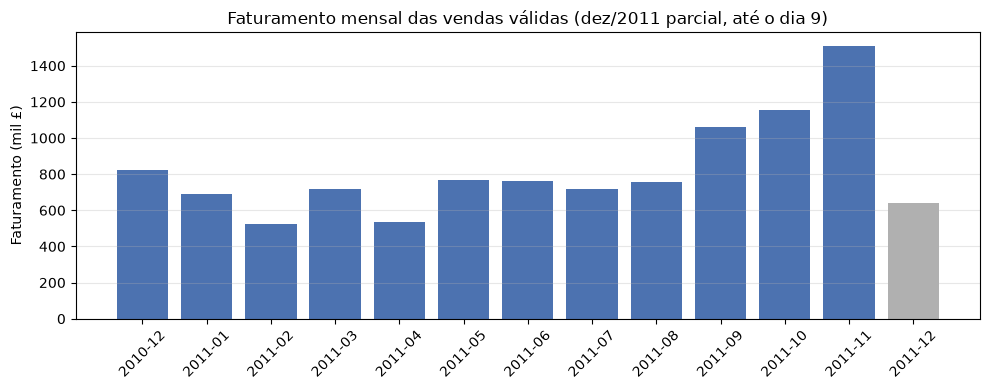

In [20]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(mensal.index.astype(str), mensal["revenue"] / 1000, color="#4C72B0")
ax.bar(str(mensal.index[-1]), mensal["revenue"].iloc[-1] / 1000, color="#B0B0B0")
ax.set_title("Faturamento mensal das vendas válidas (dez/2011 parcial, até o dia 9)")
ax.set_ylabel("Faturamento (mil £)")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**Análise:** o gráfico deixa a **sazonalidade de fim de ano** evidente: setembro, outubro e novembro somam £ 3,72 mi, **35% do faturamento do ano em apenas 3 meses**. É o padrão de uma loja de presentes e decoração, cujos clientes atacadistas se abastecem para o Natal. A barra cinza de dezembro de 2011 não é uma queda: o mês só tem dados até o dia 9.

### 9.2 Investigando os outliers

In [21]:
colunas_detalhe = ["invoice_no", "stock_code", "description", "quantity", "unit_price", "revenue", "customer_id", "country", "invoice_date"]
retail.loc[retail["quantity"].abs().ge(10_000), colunas_detalhe].sort_values("invoice_date")

,invoice_no,stock_code,description,quantity,unit_price,revenue,customer_id,country,invoice_date
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6,12346,United Kingdom,2011-01-18 10:01:00
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,-77183.6,12346,United Kingdom,2011-01-18 10:17:00
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,0.0,13256,United Kingdom,2011-11-25 15:57:00
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,16446,United Kingdom,2011-12-09 09:15:00
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.6,16446,United Kingdom,2011-12-09 09:27:00


**Análise:** as linhas com mais de 10 mil unidades revelam dois casos de **erro de lançamento**. O cliente 12346 comprou 74.215 potes de cerâmica e cancelou **16 minutos depois**, e o cliente 16446 comprou 80.995 PAPER CRAFT e cancelou **12 minutos depois**, ambos com a mesma quantidade exata. A terceira linha (12.540 adesivos) tem preço zero, então nem é venda. Nenhuma dessas linhas representa uma venda que de fato aconteceu.

In [22]:
pedidos.nlargest(10, "order_value")

,invoice_no,order_date,customer_id,country,item_quantity,order_value
19923,581483,2011-12-09 09:15:00,16446,United Kingdom,80995,168469.60
2116,541431,2011-01-18 10:01:00,12346,United Kingdom,74215,77183.60
16923,574941,2011-11-07 17:42:00,<NA>,United Kingdom,14149,52940.94
17579,576365,2011-11-14 17:55:00,<NA>,United Kingdom,13956,50653.91
8693,556444,2011-06-10 15:28:00,15098,United Kingdom,60,38970.00
13545,567423,2011-09-20 11:05:00,17450,United Kingdom,12572,31698.16
8899,556917,2011-06-15 13:37:00,12415,Australia,15049,22775.93
15693,572209,2011-10-21 12:08:00,18102,United Kingdom,1920,22206.00
13537,567381,2011-09-20 10:12:00,17450,United Kingdom,6760,22104.80
11881,563614,2011-08-18 08:51:00,12415,Australia,12196,21880.44


**Análise:** os dois maiores pedidos do ano são justamente os estornados. Depois deles aparecem pedidos grandes que parecem **atacado legítimo**: dois de cerca de £ 50 mil em novembro (sem cliente identificado) e vários de clientes recorrentes, como o 12415 da Austrália e o 17450 do Reino Unido. O pedido 556444 (60 unidades por £ 38.970, cerca de £ 650 cada) foge muito do preço típico e mereceria uma verificação com a área comercial.

In [23]:
sem_digito = ~retail["stock_code"].str.contains(r"\d")
retail.loc[sem_digito].groupby("stock_code").agg(
    descricao=("description", "first"),
    linhas=("quantity", "size"),
    valor=("revenue", "sum"),
).sort_values("linhas", ascending=False)

,descricao,linhas,valor
stock_code,,,
POST,POSTAGE,1256,66230.640
DOT,DOTCOM POSTAGE,710,206245.480
M,Manual,571,-68674.190
D,Discount,77,-5696.220
S,SAMPLES,63,-3049.390
BANK CHARGES,Bank Charges,37,-7175.639
AMAZONFEE,AMAZON FEE,34,-221520.500
CRUK,CRUK Commission,16,-7933.430
DCGSSGIRL,GIRLS PARTY BAG,13,144.430


**Análise:** os códigos sem nenhum dígito são, em sua maioria, **lançamentos que não são mercadoria**: frete (`POST`, `DOT`), lançamentos manuais (`M`), descontos (`D`), amostras (`S`), tarifas bancárias, taxas da Amazon, comissão (`CRUK`) e ajuste de dívida (`B`). As taxas da Amazon sozinhas somam −£ 221 mil. As exceções são `DCGSSGIRL`, `DCGSSBOY` (sacolas de festa) e `PADS` (enchimento de almofada), que são produtos reais e por isso ficam na base. O frete com transportadora (`C2`, CARRIAGE) tem dígito no código, então o incluí na lista à mão.

### 9.3 Critérios e base limpa

Com base no diagnóstico das seções 5, 8 e 9.2, estes são os critérios que adoto:

| Conceito | Critério | Por quê |
|---|---|---|
| **Venda válida** | Nota sem prefixo `C`, `quantity > 0`, `unit_price > 0`, código de **produto** e que **não foi estornada integralmente logo em seguida** | É o que de fato gerou receita com mercadoria |
| **Cancelamento** | Nota com prefixo `C` | É o código que o próprio sistema usa para estornos |
| **Devolução** | Não dá para separar de cancelamento: o dataset registra os dois do mesmo jeito (nota `C`, quantidade negativa) | Tratar como a mesma categoria e deixar essa limitação clara |
| **Ajuste de estoque** | Quantidade negativa **sem** nota `C` (todas com preço zero e sem cliente) | Não envolve dinheiro nem cliente: é movimentação interna |
| **Registro anômalo** | Códigos que não são produto (frete, taxas, lançamentos manuais, descontos, amostras, ajuste de dívida) e as duas linhas gigantes estornadas minutos depois | Distorcem rankings e totais de produto |

**Decisões que mantive como no roteiro:**

- **Compras grandes de atacado ficam.** Pedidos de 12 a 15 mil unidades de clientes recorrentes, como o 12415 da Austrália, são vendas legítimas: o dataset é de uma loja com muitos clientes atacadistas.
- **Linhas duplicadas ficam.** São 0,97% da base e podem ser o mesmo item lançado duas vezes de propósito. Sem como confirmar, prefiro não apagar receita real.
- **Vendas sem cliente identificado ficam nos totais** e saem só do ranking de clientes.

In [24]:
codigos_nao_produto = ["POST", "DOT", "C2", "M", "m", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK", "B"]

cancelamentos_gigantes = retail.loc[
    retail["is_cancelled"] & retail["quantity"].le(-10_000), ["customer_id", "stock_code", "quantity"]
]
cancelamentos_gigantes = cancelamentos_gigantes.assign(quantity=-cancelamentos_gigantes["quantity"])
linhas_estornadas = vendas.reset_index().merge(cancelamentos_gigantes, on=["customer_id", "stock_code", "quantity"])["index"]

nao_produto = vendas["stock_code"].isin(codigos_nao_produto)
vendas_limpas = vendas.loc[~nao_produto & ~vendas.index.isin(linhas_estornadas)].copy()

print(f"Linhas removidas por não serem produto: {nao_produto.sum():,} (£ {vendas.loc[nao_produto, 'revenue'].sum():,.2f})")
print(f"Linhas removidas por terem sido estornadas logo depois: {len(linhas_estornadas)} (£ {vendas.loc[linhas_estornadas, 'revenue'].sum():,.2f})")
print(f"Linhas na base limpa: {len(vendas_limpas):,}")

Linhas removidas por não serem produto: 2,312 (£ 394,565.67)
Linhas removidas por terem sido estornadas logo depois: 2 (£ 245,653.20)
Linhas na base limpa: 527,790


**Análise:** a base limpa remove **2.312 linhas que não são produto** (£ 394.565,67, quase tudo frete) e as **2 linhas estornadas logo em seguida** (£ 245.653,20), e fica com 527.790 linhas. Os critérios são explícitos e reproduzíveis: qualquer pessoa que rodar o notebook chega à mesma base.

In [25]:
def resumo(base):
    pedidos_base = base.groupby("invoice_no")["revenue"].sum()
    return pd.Series(
        {
            "linhas": len(base),
            "pedidos": base["invoice_no"].nunique(),
            "faturamento": base["revenue"].sum(),
            "ticket_medio": pedidos_base.mean(),
            "ticket_mediano": pedidos_base.median(),
        }
    )


pd.DataFrame({"roteiro": resumo(vendas), "base limpa": resumo(vendas_limpas)}).round(2)

,roteiro,base limpa
linhas,530104.00,527790.00
pedidos,19960.00,19771.00
faturamento,10666684.54,10026465.67
ticket_medio,534.40,507.13
ticket_mediano,303.84,302.58


**Análise:** com os critérios aplicados, o faturamento de mercadorias cai **6%**, de £ 10,67 mi para **£ 10,03 mi**, e o ticket médio cai de £ 534,40 para £ 507,13. Já o **ticket mediano quase não muda** (£ 303,84 → £ 302,58). É a prova prática de que a mediana é robusta a outliers: tirar os dois pedidos gigantes mexe na média, mas não no pedido típico.

In [26]:
vendas_limpas.groupby(["stock_code", "description"], as_index=False).agg(
    revenue=("revenue", "sum"),
    units_sold=("quantity", "sum"),
    order_count=("invoice_no", "nunique"),
).nlargest(10, "revenue").round(2)

,stock_code,description,revenue,units_sold,order_count
1340,22423,REGENCY CAKESTAND 3 TIER,174484.74,13879,1988
3639,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104340.29,37599,2189
2876,47566,PARTY BUNTING,99504.33,18295,1685
3618,85099B,JUMBO BAG RED RETROSPOT,94340.05,48474,2089
2029,23084,RABBIT NIGHT LIGHT,66964.99,30788,994
1022,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64952.29,19355,1160
3415,84879,ASSORTED COLOUR BIRD ORNAMENT,59094.93,36461,1455
3058,79321,CHILLI LIGHTS,54117.76,10306,661
2285,23298,SPOTTY BUNTING,42548.13,8327,1140
1307,22386,JUMBO BAG PINK POLKADOT,42436.24,21465,1218


**Análise:** sem frete e sem os pedidos estornados, o top 10 de faturamento passa a ter **só mercadorias reais**, e quase todas são produtos frequentes (de 661 a 2.189 pedidos). O `REGENCY CAKESTAND 3 TIER` lidera com £ 174 mil, e aparecem itens de Natal como o `PAPER CHAIN KIT 50'S CHRISTMAS`, coerente com a sazonalidade da seção 9.1. É este ranking, e não o da seção 7.2, que deveria ir para o gerente.

## 10. Recomendações para a gerência de vendas

**1. Planejar o ano em torno do quarto trimestre.** Setembro a novembro concentram 35% do faturamento (£ 3,72 mi), e novembro sozinho fatura quase 3 vezes fevereiro. O estoque dos produtos mais frequentes e dos itens de Natal precisa estar pronto **antes de setembro**, e as campanhas comerciais devem começar em agosto. Nos meses fracos (fevereiro e abril), ações de reativação de clientes podem suavizar a queda.

**2. Proteger as contas-chave internacionais e diversificar esses mercados.** Holanda, Irlanda e Austrália estão entre os 6 maiores mercados, mas dependem de 1 a 2 clientes cada (de 90% a 98% do faturamento do país). Perder um único cliente derrubaria o mercado inteiro. Recomendo um atendimento dedicado a essas contas e prospecção de novos clientes nesses países, seguindo o modelo de Alemanha e França, que têm cerca de 90 clientes cada.

**3. Reduzir cancelamentos e validar pedidos atípicos.** Fora os dois pedidos lançados por engano, os cancelamentos ainda somam **£ 651 mil (6,5% do faturamento de mercadorias)**. Vale investigar as causas mais comuns por produto e por cliente. Além disso, os dois pedidos gigantes (£ 246 mil) foram desfeitos em minutos, então uma **confirmação obrigatória para pedidos acima de 10 mil unidades** evitaria lançamentos errados que distorcem os relatórios.

**4. Identificar o cliente em toda venda.** Um quarto das linhas (24,9%) não tem cliente, incluindo pedidos grandes de £ 50 mil. Sem isso não dá para fazer fidelização, segmentação nem análise de recorrência. Exigir o cadastro no fechamento do pedido aumenta o valor dos dados de vendas.

**5. Separar frete e taxas dos produtos nos relatórios.** O "produto" que mais faturou no relatório bruto foi o frete (`DOTCOM POSTAGE`). Relatórios de desempenho de produto devem usar a base limpa, para que decisões de catálogo sejam tomadas sobre mercadorias reais.

## Perguntas para consolidar

**1. Cancelamento e devolução são a mesma coisa? O filtro que trata `is_cancelled` e quantidade negativa juntos é preciso o bastante?**

Não totalmente. A seção 8 mostrou que nem toda quantidade negativa é cancelamento: das 10.624 linhas negativas, **1.336 não têm nota `C`**, e todas elas têm preço zero e nenhum cliente, ou seja, são ajustes internos de estoque com impacto financeiro zero. Já devolução e cancelamento **não podem ser separados** com esses dados, porque o sistema registra os dois como nota `C` com quantidade negativa. Por isso, na minha análise, "cancelamentos e devoluções" formam uma categoria só (as notas `C`), e os ajustes de estoque ficam à parte.

**2. Quando um outlier é erro e quando é atacado legítimo? É seguro apagar as linhas com quantidades de dezenas de milhares?**

Não é seguro apagar por um limite de quantidade. É preciso olhar caso a caso, como na seção 9.2. As duas maiores linhas (74.215 e 80.995 unidades) são **erros**: o mesmo cliente cancelou a mesma quantidade minutos depois. Já pedidos de 12 a 15 mil unidades de clientes recorrentes, como o 12415 da Austrália, são **atacado legítimo**, coerente com uma loja que vende para revendedores. Apagar tudo acima de um limite jogaria fora vendas reais dos melhores clientes.

**3. Qual recorte de "vendas válidas" você defende?**

O da base limpa (seção 9.3): nota sem `C`, quantidade e preço positivos, apenas códigos de produto e sem as linhas estornadas logo em seguida. As **2.475 linhas com preço zero e cliente ausente** que a Aula 02 encontrou já ficam de fora pela regra de preço positivo, e é o certo: sem preço, sem cliente e quase sempre sem descrição, elas parecem brindes, amostras ou ajustes de estoque, não vendas. O recorte custa 6% do faturamento bruto, mas deixa os rankings de produto e de cliente fiéis ao que de fato foi vendido.

## Conclusão

O roteiro mostrou como transformar a base bruta em indicadores: ticket médio, rankings de produtos, países e clientes, e o impacto dos cancelamentos. O "Para casa" mostrou que **o filtro inicial não basta**: o frete aparecia como produto nº 1, e dois pedidos lançados por engano criavam um falso 3º produto mais vendido e dois falsos grandes clientes. Com critérios explícitos, a base limpa soma £ 10,03 mi em mercadorias e revela os padrões que importam para o negócio: forte concentração no Reino Unido, mercados internacionais dependentes de poucos clientes, cancelamentos em torno de 6,5% do faturamento e uma sazonalidade marcada, com o quarto trimestre respondendo por mais de um terço do ano.